# Spectral Line Energy Distribution (SLED)

This example notebook shows how to calculate a model SLED. We consider CO emitted from the ISM of a galaxy. In this simple example, we vary the kinetic temperature and gas density individually. In a more realistic application, one would instead vary the parameters jointly on a grid. Also, additional parameters (such as the column density) could be explored.

In [1]:
from pythonradex import radiative_transfer, helpers
from scipy import constants
import matplotlib.pyplot as plt
import numpy as np

In [2]:
datafilepath = "./co.dat" # file downloaded from EMAA or LAMDA database
geometry = "LVG sphere" #spherical large velocity gradient
line_profile_type = "rectangular"
width_v = 200 * constants.kilo #typical line width for galaxies
source = radiative_transfer.Source(
    datafilepath=datafilepath,
    geometry=geometry,
    line_profile_type=line_profile_type,
    width_v=width_v,
    use_datafile_frequencies=True,
)

We assume a  [CO]/[H$_2$] abundance of $3\times10^{-4}$, a H$_2$ column density of $10^{22}$ cm$^{-2}$, and a H$_2$ number density of $10^3$ cm$^{-3}$

In [3]:
CO_to_H2_abundance = 3e-4
N_H2 = 1e22/constants.centi**2
N_CO = N_H2*CO_to_H2_abundance

#for simplicity, assume ortho/para=1
collider_densities = {
    "para-H2": 0.5e3 / constants.centi**3,
    "ortho-H2": 0.5e3 / constants.centi**3,
}

#assumed the galaxy is at redshift z=1
ext_background = helpers.generate_CMB_background(z=1)

T_dust = tau_dust = 0 # for simplicity, no dust in this example

source.update_parameters(
    N=N_CO,
    Tkin=100, #set arbitrary value here; we will vary it below
    collider_densities=collider_densities,
    ext_background=ext_background,
    T_dust=T_dust,
    tau_dust=tau_dust,
)

Now let us calculate models for a few different kinetic temperatures. We plot the SLED (normalised to CO 1-0) for the ten lowest transitions of CO.

/home/gianni/science/projects/code/pythonradex/pythonradex/src/pythonradex/radiative_transfer.py:437: UserWarning: negative optical depth! 1-0: tau_nu0 = -0.2
  warnings.warn(warn_message)


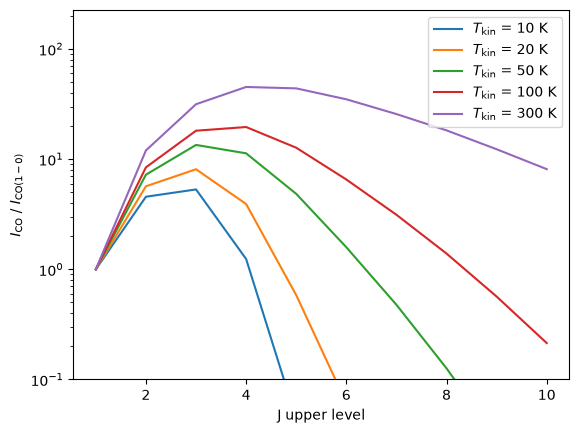

In [4]:
Tkin_values = [10,20,50,100,300]
transition_indices = np.arange(10)
J_upper = transition_indices+1 #verified that this is true in the datafile (co.dat)

fig,ax = plt.subplots()

for Tkin in Tkin_values:
    source.update_parameters(Tkin=Tkin)
    source.solve_radiative_transfer()
    intensities = source.frequency_integrated_emission(
                      output_type="intensity", transitions=transition_indices)
    SLED = intensities / intensities[0] #normalise by J=1-0
    ax.plot(J_upper,SLED,label=rf"$T_\mathrm{{kin}}$ = {Tkin} K")

ax.set_xlabel("J upper level")
ax.set_ylabel(r"$I_\mathrm{CO}$ / $I_\mathrm{CO (1-0)}$")
ax.set_yscale("log")
ax.set_ylim(ymin=0.1)
ax.legend(loc="best")

We see how the SLED shifts as the kinetic temperature increases; for higher temperatures, higher J transitions become stronger.

Next, we do a similar calculation by varying the H$_2$ density, keeping the kinetic temperature fixed.

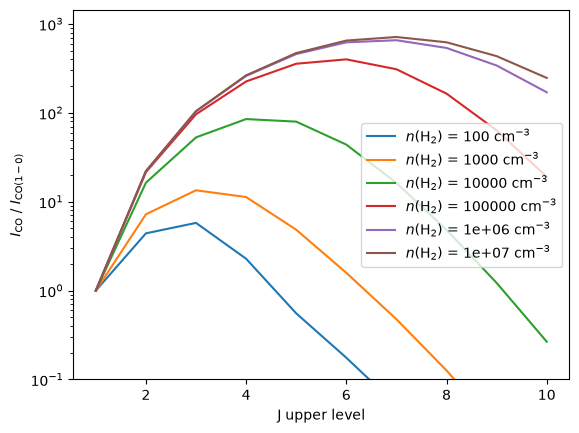

In [5]:
nH2_values = 10**np.arange(2,8) / constants.centi**3
source.update_parameters(Tkin=50) #fix the temperature

fig,ax = plt.subplots()

for nH2 in nH2_values:
    collider_densities = {"para-H2": nH2/2,"ortho-H2": nH2/2,}
    source.update_parameters(collider_densities=collider_densities)
    source.solve_radiative_transfer()
    intensities = source.frequency_integrated_emission(
                      output_type="intensity", transitions=transition_indices)
    SLED = intensities / intensities[0] #normalise by J=1-0
    ax.plot(J_upper,SLED,label=rf"$n(\mathrm{{H}}_2)$ = {nH2/constants.centi**-3:g} cm$^{{-3}}$")

ax.set_xlabel("J upper level")
ax.set_ylabel(r"$I_\mathrm{CO}$ / $I_\mathrm{CO (1-0)}$")
ax.set_yscale("log")
ax.set_ylim(ymin=0.1)
ax.legend(loc="best")

We see how the emission from higher J transitions increases as the gas density increases. For the highest densities, LTE seems established (i.e. the intensity becomes independent of the gas density).